# 03 · GBDT baseline

**Goal:** train the base model and establish what we can trust about it before any conformal machinery is added.

1. Fit LightGBM (early stopping on a validation split carved **from `train` only**).
2. Check that `calib_fit`, `calib` and `test` behave alike (they are exchangeable ID samples). A large gap means a bug.
3. Look at calibration and feature importance.
4. Run the **10-seed protocol** on the base model.
5. See what shift does to accuracy and to a plain confidence score (a *preview*; the formal OOD baselines come in the next stage).

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from conformal_trees.data import build_covariate_shifts, load_dataset, make_splits
from conformal_trees.evaluation import classification_report, ood_report
from conformal_trees.models import GBDTClassifier
from conformal_trees.utils import load_config, set_global_seed

pd.set_option("display.max_columns", 50)
cfg = load_config("base.yaml", "models.yaml", "ood_scenarios.yaml")
SEED = cfg["project"]["default_seed"]
set_global_seed(SEED)

ds = load_dataset("adult")
splits = make_splits(ds.X, ds.y, cfg["splits"], seed=SEED)

## 1. Fit

In [10]:
model = GBDTClassifier.from_config(cfg["gbdt"], seed=SEED).fit(splits.train.X, splits.train.y)
print(f"trees kept by early stopping: {model.best_iteration_}")

trees kept by early stopping: 2000


## 2. Performance per split
`calib_fit`, `calib` and `test` should agree up to sampling noise. `train` will be better (the model has seen it).

In [11]:
report = pd.DataFrame({
    name: classification_report(s.y, model.predict_proba(s.X)[:, 1]) for name, s in splits
}).T
report.round(4)

,accuracy,balanced_accuracy,auroc,log_loss,brier,ece
train,0.9466,0.9171,0.9871,0.1454,0.0425,0.0406
calib_fit,0.8593,0.7897,0.9162,0.3153,0.0987,0.0399
calib,0.8619,0.7844,0.9145,0.3172,0.0978,0.0380
test,0.8631,0.7926,0.9163,0.3115,0.0962,0.0351


## 3. Calibration and feature importance

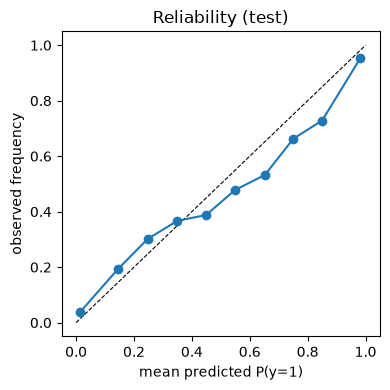

In [12]:
p, y = model.predict_proba(splits.test.X)[:, 1], splits.test.y
edges = np.linspace(0, 1, 11)
idx = np.digitize(p, edges[1:-1])
conf = [p[idx == b].mean() for b in range(10) if (idx == b).any()]
freq = [y[idx == b].mean() for b in range(10) if (idx == b).any()]

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.plot(conf, freq, "o-")
ax.set_xlabel("mean predicted P(y=1)"); ax.set_ylabel("observed frequency"); ax.set_title("Reliability (test)")
plt.tight_layout(); plt.show()

In [13]:
model.feature_importance().to_frame().round(1)

,importance
age,37397.0
relationship,32907.8
education-num,25603.9
capital-gain,25124.0
hours-per-week,21949.2
occupation,15975.1
marital-status,14895.8
capital-loss,9056.7
workclass,4003.7
native-country,3415.7


## 4. The 10-seed protocol
Every number in the paper will be mean ± std over the seeds in `configs/base.yaml`. The split changes with the seed too.

In [14]:
rows = []
for seed in cfg["project"]["seeds"]:
    sp = make_splits(ds.X, ds.y, cfg["splits"], seed=seed)
    m = GBDTClassifier.from_config(cfg["gbdt"], seed=seed).fit(sp.train.X, sp.train.y)
    r = classification_report(sp.test.y, m.predict_proba(sp.test.X)[:, 1])
    rows.append({"seed": seed, **r})
runs = pd.DataFrame(rows).set_index("seed")
runs.agg(["mean", "std"]).round(4)

,accuracy,balanced_accuracy,auroc,log_loss,brier,ece
mean,0.8603,0.7863,0.9153,0.3154,0.0979,0.0383
std,0.0019,0.0030,0.0017,0.0037,0.0012,0.0021


## 5. What shift does (preview)
For each scenario we shift the `test` rows and measure (a) accuracy against the original labels, (b) the model's mean confidence, and (c) how well a plain confidence score separates ID from shifted rows.

The score is `1 - max(p, 1-p)` (higher = less confident = more OOD). This is a *preview*, not a final baseline.

In [15]:
X_id, y_id = splits.test.X, splits.test.y
p_id = model.predict_proba(X_id)[:, 1]
conf_id = np.maximum(p_id, 1 - p_id)
shifts = build_covariate_shifts(cfg, splits.train.X, ds.numeric)

rows = []
for s in shifts:
    p_ood = model.predict_proba(s.apply(X_id, seed=SEED))[:, 1]
    conf_ood = np.maximum(p_ood, 1 - p_ood)
    rows.append({
        "kind": s.kind, "severity": s.severity,
        "accuracy": classification_report(y_id, p_ood)["accuracy"],
        "mean_confidence": conf_ood.mean(),
        "conf_auroc": ood_report(1 - conf_id, 1 - conf_ood)["auroc"],
    })
shift_df = pd.DataFrame(rows)
print(f"ID reference: accuracy={classification_report(y_id, p_id)['accuracy']:.4f}, mean_confidence={conf_id.mean():.4f}")
shift_df.round(4)

ID reference: accuracy=0.8631, mean_confidence=0.8972


,kind,severity,accuracy,mean_confidence,conf_auroc
0,mean_shift,0.25,0.8493,0.8861,0.5404
1,mean_shift,0.50,0.8416,0.8735,0.5745
2,mean_shift,1.00,0.7960,0.8546,0.6244
3,mean_shift,2.00,0.7272,0.8103,0.7127
4,mean_shift,4.00,0.8214,0.8904,0.6362
5,gaussian_noise,0.25,0.8557,0.9011,0.4960
6,gaussian_noise,0.50,0.8556,0.9062,0.4850
7,gaussian_noise,1.00,0.8332,0.9172,0.4615
8,gaussian_noise,2.00,0.8214,0.9327,0.4255
9,gaussian_noise,4.00,0.8152,0.9425,0.3989


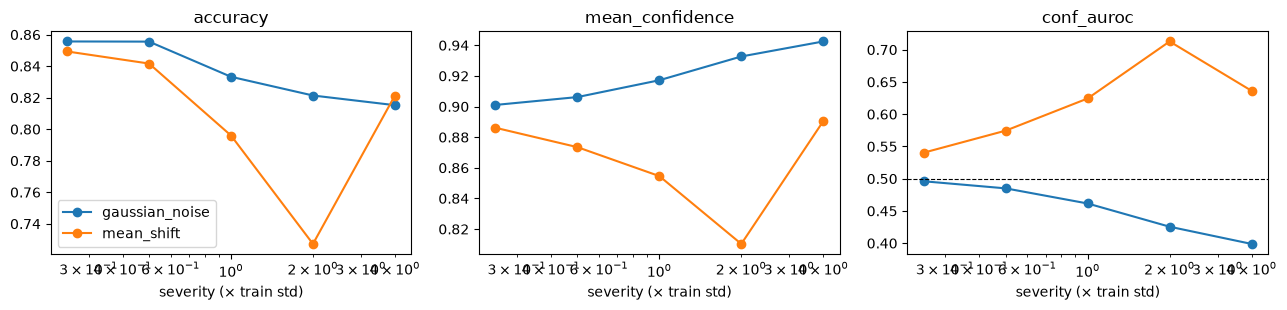

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for kind, g in shift_df.groupby("kind"):
    for ax, col in zip(axes, ["accuracy", "mean_confidence", "conf_auroc"]):
        ax.plot(g["severity"], g[col], "o-", label=kind); ax.set_title(col); ax.set_xscale("log")
        ax.set_xlabel("severity (× train std)")
axes[2].axhline(0.5, color="k", ls="--", lw=0.8); axes[0].legend()
plt.tight_layout(); plt.show()

Read this carefully and **do not over-interpret on one seed**. The question to answer: when accuracy drops, does the confidence score notice? Where it does not, that gap is what the OOD layer has to close.
Record observations in `docs/decisions.md`.